<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/7_5_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile dft_toplam.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>
#include <random>

const double PI = std::acos(-1.0);

// Sinüs Sinyali Üretici
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();
    for (size_t i = 0; i < n; ++i) {
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

// Gürültü Ekleyici
void addNoise(std::vector<double>& vec, double noise_ratio) {
    double max_amp = 0.0;
    for (double v : vec) if (std::abs(v) > max_amp) max_amp = std::abs(v);

    double bound = max_amp * noise_ratio;
    std::random_device rd;
    std::mt19937 gen(rd());
    std::uniform_real_distribution<> dis(-bound, bound);

    for (double& v : vec) v += dis(gen);
}

// 1D Ayrık Fourier Dönüşümü (DFT)
std::vector<double> computeDFT(const std::vector<double>& input_signal) {
    size_t N = input_signal.size();
    std::vector<double> magnitude_spectrum(N, 0.0);

    for (size_t k = 0; k < N; ++k) {
        double real_sum = 0.0;
        double imag_sum = 0.0;

        for (size_t x = 0; x < N; ++x) {
            double angle = 2.0 * PI * k * x / N;
            real_sum += input_signal[x] * std::cos(angle);
            imag_sum -= input_signal[x] * std::sin(angle);
        }
        magnitude_spectrum[k] = std::sqrt(real_sum * real_sum + imag_sum * imag_sum) / N;
    }
    return magnitude_spectrum;
}

int main() {
    size_t N = 512; // 2^9 boyutunda vektör (Frekansları net görebilmek için)

    // ==========================================
    // 1. SİNYAL: Frekans = 50, Genlik = 12
    // ==========================================
    std::vector<double> sig1(N);
    generateSineWave(sig1, 12.0, 50.0, 0.0);
    addNoise(sig1, 0.30); // %30 gürültü ekle

    // ==========================================
    // 2. SİNYAL: Frekans = 30, Genlik = 5
    // ==========================================
    std::vector<double> sig2(N);
    generateSineWave(sig2, 5.0, 30.0, 0.0);
    addNoise(sig2, 0.30); // %30 gürültü ekle

    // ==========================================
    // 3. TOPLAM SİNYAL: İki sinyalin üst üste binmesi
    // ==========================================
    std::vector<double> sig_sum(N);
    for (size_t i = 0; i < N; ++i) {
        sig_sum[i] = sig1[i] + sig2[i];
    }

    // ==========================================
    // 4. DFT (Frekans Uzayına Dönüşüm) İŞLEMLERİ
    // ==========================================
    std::vector<double> harm1 = computeDFT(sig1);
    std::vector<double> harm2 = computeDFT(sig2);
    std::vector<double> harm_sum = computeDFT(sig_sum);

    // Python ile görselleştirmek için CSV dosyasına yazdır
    std::ofstream outFile("dft_toplam_verisi.csv");
    outFile << "Index,Sig1,Sig2,SigSum,Harm1,Harm2,HarmSum\n";
    for (size_t i = 0; i < N; ++i) {
        outFile << i << "," << sig1[i] << "," << sig2[i] << "," << sig_sum[i] << ","
                << harm1[i] << "," << harm2[i] << "," << harm_sum[i] << "\n";
    }
    outFile.close();

    std::cout << "Sinyaller basariyla uretildi, DFT analizleri yapildi ve diske kaydedildi." << std::endl;
    return 0;
}

Writing dft_toplam.cpp


In [2]:
!g++ dft_toplam.cpp -o dft_toplam
!./dft_toplam

Sinyaller basariyla uretildi, DFT analizleri yapildi ve diske kaydedildi.


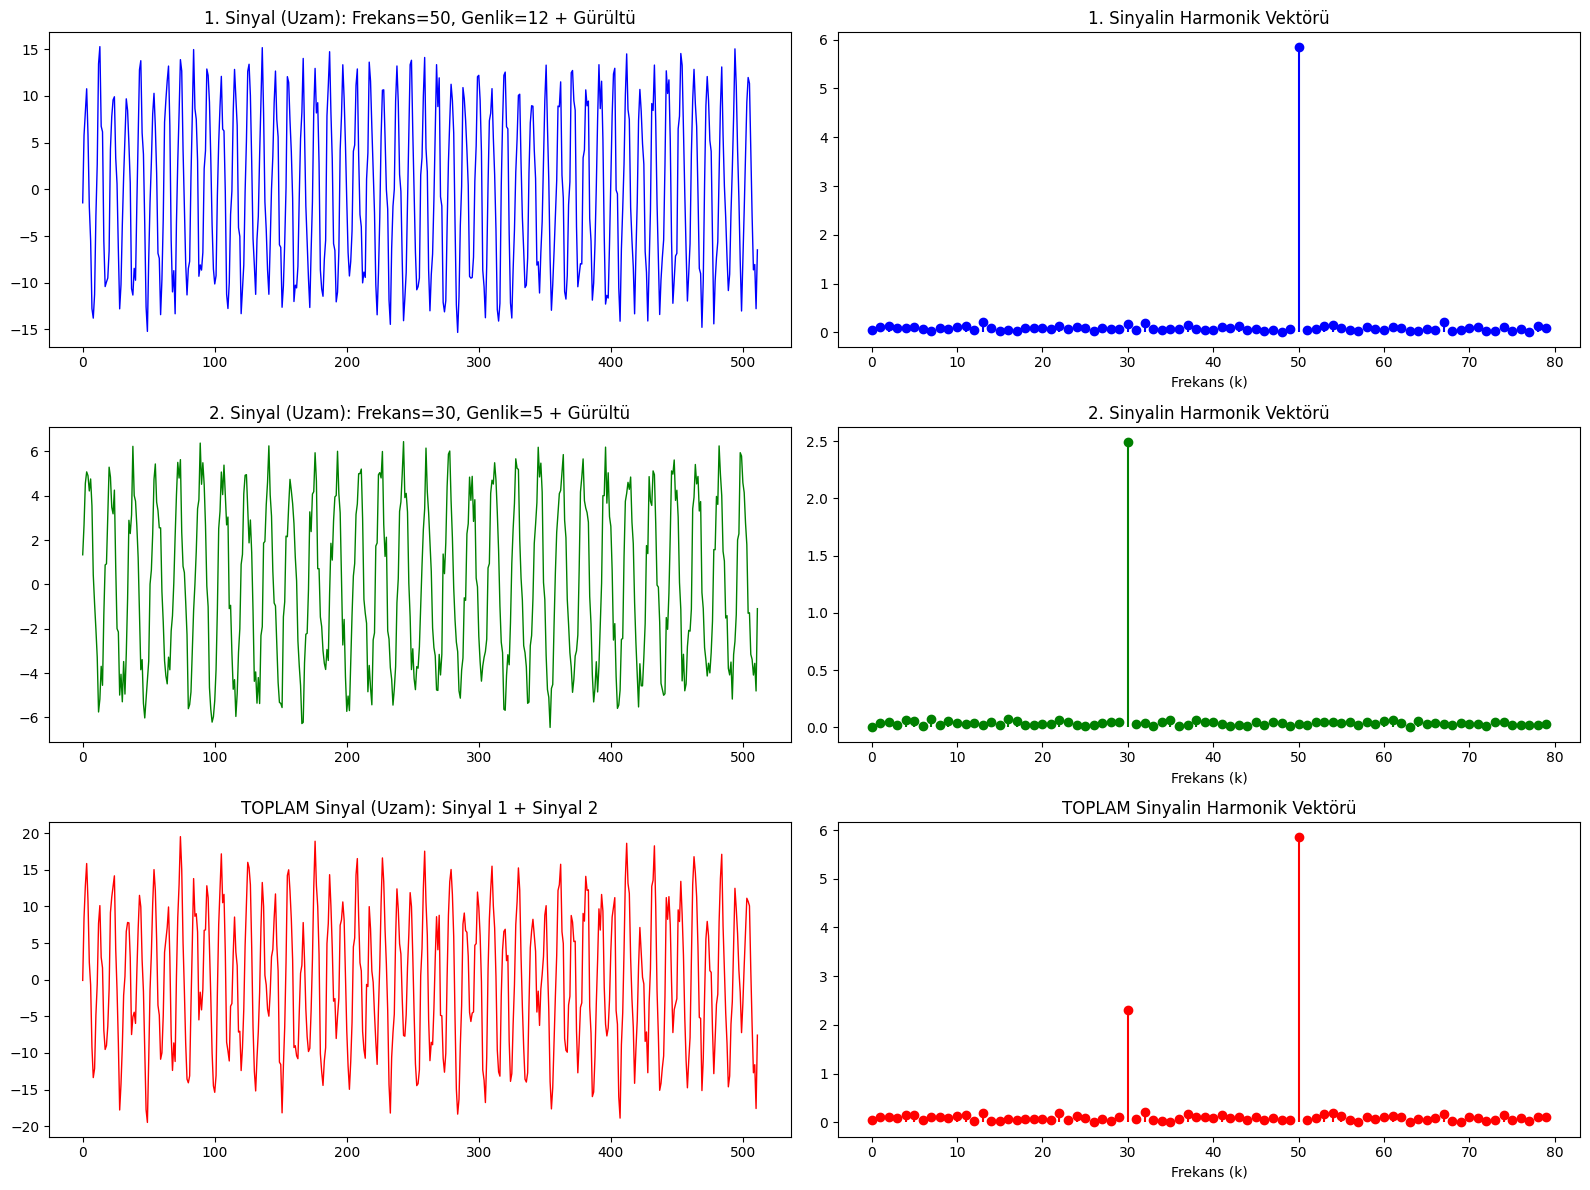

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('dft_toplam_verisi.csv')

# Zirveleri (30 ve 50) net görebilmek için x eksenini 0'dan 80'e kadar kısıtlıyoruz
view_limit = 80

plt.figure(figsize=(16, 12))

# --- 1. Sinyal (Frekans: 50, Genlik: 12) ---
plt.subplot(3, 2, 1)
plt.plot(df['Index'], df['Sig1'], color='blue', linewidth=1)
plt.title('1. Sinyal (Uzam): Frekans=50, Genlik=12 + Gürültü')

plt.subplot(3, 2, 2)
plt.stem(df['Index'][:view_limit], df['Harm1'][:view_limit], linefmt='blue', basefmt=" ")
plt.title('1. Sinyalin Harmonik Vektörü')
plt.xlabel('Frekans (k)')

# --- 2. Sinyal (Frekans: 30, Genlik: 5) ---
plt.subplot(3, 2, 3)
plt.plot(df['Index'], df['Sig2'], color='green', linewidth=1)
plt.title('2. Sinyal (Uzam): Frekans=30, Genlik=5 + Gürültü')

plt.subplot(3, 2, 4)
plt.stem(df['Index'][:view_limit], df['Harm2'][:view_limit], linefmt='green', basefmt=" ")
plt.title('2. Sinyalin Harmonik Vektörü')
plt.xlabel('Frekans (k)')

# --- 3. Toplam Sinyal (Sig1 + Sig2) ---
plt.subplot(3, 2, 5)
plt.plot(df['Index'], df['SigSum'], color='red', linewidth=1)
plt.title('TOPLAM Sinyal (Uzam): Sinyal 1 + Sinyal 2')

plt.subplot(3, 2, 6)
plt.stem(df['Index'][:view_limit], df['HarmSum'][:view_limit], linefmt='red', basefmt=" ")
plt.title('TOPLAM Sinyalin Harmonik Vektörü')
plt.xlabel('Frekans (k)')

plt.tight_layout()
plt.show()